# Twitter Sentiment Analysis

## Importing Dependencies

In [0]:
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
pd.set_option('display.max_columns', 100) # Show 100 columns when looking at dataframe
import itertools
import re
import tweepy

## Data Collection

*GO to [Twitter](https://developer.twitter.com). Click on Apply.*

*Fill out all the questions that are being asked and you will get access to the API Tokens.*

*Make sure Tweepy is installed otherwise just do !pip install tweepy on your jupyter notebook*

### Streaming With Tweepy

In [0]:
#!pip install tweepy

In [0]:
#Import the necessary methods from tweepy library
from tweepy.streaming import StreamListener
from tweepy import OAuthHandler ## Authencation
from tweepy import Stream

In [0]:
access_token = "YOUR_ACCESS_TOKEN"
access_token_secret = "YOUR_ACCESS_TOKEN_SECRET"
consumer_key = "YOUR_CONSUMER_KEY"
consumer_secret = "YOUR_CONSUMER_SECRET"

In [0]:
auth = OAuthHandler(consumer_key, consumer_secret) 
auth.set_access_token(access_token, access_token_secret)

In [0]:
## for continuous streaming till keyboard interruption
## child class/ inherited class
class StdOutListener(StreamListener):
    def on_status(self, data):
        print (data.text)
        return True

    def on_error(self, status):
        print (status)
        return False

In [0]:
l = StdOutListener()
stream = Stream(auth, l)

In [0]:
#This line filter Twitter Streams to capture data by the keywords: '#ArtificialIntelligence'
stream.filter(track=['#Article370'])

RT @SirJadeja: Bold steps taken by Pak to force us to revoke scrapping of #Article370
✅Stopped bilateral trades
✅Stopped Samjhauta Express…
हमें #Kashmir घाटी से संगिठत तरीके से निकाला गया: #Kashmiripandit
@Nuruddin_4
#NarendraModi #Article370 
https://t.co/o60R5nTAEO
RT @arabnewspk: It’s been more than two weeks since #Indian administered #Kashmir has been facing a security lockdown and prohibitory order…
RT @NooriBadat: #Jammu has turned out to be a safe destination for students of #Kashmir after the abrogation of #Article370. The students,…
RT @AnasMallick: Just In: Pakistani Prime Minister @ImranKhanPTI has telephoned German Chancellor Angela Merkel and apprised him about Paki…
RT @htTweets: #Article370 scrapped: Chartered Accountant institute to open chapter in Jammu-Kashmir, Ladakh

(report by @JayaswalRajeev)

h…
RT @IWF_Writers: “The blackout is a form of collective punishment of the people of J &amp; K, without even a pretext of a precipitating offence…
RT @AnasMallick: Just I

KeyboardInterrupt: ignored

In [0]:
## Control the no. of tweets
class StdOutListener_control(StreamListener):
    def __init__(self, api=None):
        super(StdOutListener_control, self).__init__()
        self.num_tweets = 0
        
    def on_status(self, data):
        print (data.text)
        self.num_tweets += 1
        if self.num_tweets < 20:
            return True
        else:
            return False
    def on_error(self, status):
        print (status)
        return False

In [0]:
l_control = StdOutListener_control()
stream = Stream(auth, l_control)

In [0]:
stream.filter(track=['#Article370'])

Her, not him
RT @SirJadeja: Bold steps taken by Pak to force us to revoke scrapping of #Article370
✅Stopped bilateral trades
✅Stopped Samjhauta Express…
RT @SalmanSoz: My open letter to PM @narendramodi ji.

The PM spoke of development, corruption, and terrorism while justifying his govt's d…
RT @BBCUrdu: سرینگر میں عام شہریوں کا دعویٰ ہے کہ اب بھی سیکیورٹی اہلکار آدھی رات کو ان کے گھروں پر چھاپے مارتے ہیں۔
#Kashmir #India #Pakis…
RT @BBCUrdu: سرینگر میں عام شہریوں کا دعویٰ ہے کہ اب بھی سیکیورٹی اہلکار آدھی رات کو ان کے گھروں پر چھاپے مارتے ہیں۔
#Kashmir #India #Pakis…
RT @TheDeshBhakt: Dear @UNGeneva,
Please be informed that you are spreading #FakeNews.
The best reporters &amp; the most senior editors have sh…
RT @SirJadeja: Bold steps taken by Pak to force us to revoke scrapping of #Article370
✅Stopped bilateral trades
✅Stopped Samjhauta Express…
RT @AnasMallick: Just In: Pakistani Prime Minister @ImranKhanPTI has telephoned German Chancellor Angela Merkel and apprised him about Paki

In [0]:
# controlling and saving number of tweets
class StdOutListener_control_save(StreamListener):
    def __init__(self, api=None):
        super(StdOutListener_control_save, self).__init__()
        self.num_tweets = 0
        self.text = list([])
        self.created_at = list([])
        self.author = list([])
    def on_status(self, data):
        print (data.text)
        self.num_tweets += 1
        if hasattr(data,'extended_tweet'):
            t = data.extended_tweet['full_text']
        else:
            t = data.text
        ct= data.created_at
        aut= data.author.name
        if self.num_tweets < 200:
            self.text.append(t)
            self.created_at.append(ct)
            self.author.append(aut)
            return True
        else:
            return False
    def on_error(self, status):
        print (status)
        return False

In [0]:
l_save = StdOutListener_control_save()
stream = Stream(auth, l_save)

In [0]:
stream.filter(track=['#Article370'], languages=["en"])

RT @arabnewspk: It’s been more than two weeks since #Indian administered #Kashmir has been facing a security lockdown and prohibitory order…
RT @drishtikone: Mindboggling games of betrayal and intrigue and internecine rivalry of Indian agencies in Kashmir #IntrigueinKashmir #Arti…
RT @neelakantha: Imposters, who pretended to be #Hindus from #Kashmir, only to support the #Jehadi propaganda on #Article370, nailed.
Over…
@carriesymonds Sir
With all respect
you will be reading me again and again until you break your silence.… https://t.co/Vo83cBqFZz
@carriesymonds Ask @UN
Ask @antonioguterres
Why are they silent?
Someone please wake them up from the deep sleep.
H… https://t.co/mUck6XFQJS
Solution of Kashmir issue doesn't lie in #Article370. Genesis of Kashmir issue doesn't lie in Article 370.  @AmanHingorani at @ieexplained
RT @SalmanSoz: Asgar Ali Karbalai is one of Kargil's seniormost leaders. The people of Kargil have also rejected the recent move on Article…
RT @SirJadeja: Bold steps t

In [0]:
l_save.num_tweets

200

In [0]:
import pandas as pd

In [0]:
collection = pd.DataFrame({"Text":l_save.text,"Creation":l_save.created_at,"author":l_save.author})

In [0]:
collection['word_count'] = collection['Text'].apply(lambda x: len(str(x).split(" ")))

In [0]:
collection['character_count'] = [len(wc) for wc in collection['Text']]

In [0]:
collection.head()

,Text,Creation,author,word_count,character_count
0,RT @arabnewspk: It’s been more than two weeks ...,2019-08-23 13:22:46,Nimra Nayab,21,140
1,RT @drishtikone: Mindboggling games of betraya...,2019-08-23 13:22:50,danny,18,140
2,"RT @neelakantha: Imposters, who pretended to b...",2019-08-23 13:23:19,Kalpeshco,19,139
3,@carriesymonds Sir\nWith all respect\nyou will...,2019-08-23 13:23:22,Malik Sohaib Adeel,24,291
4,@carriesymonds Ask @UN\nAsk @antonioguterres\n...,2019-08-23 13:23:38,Malik Sohaib Adeel,21,284


In [0]:
collection.head()

,Text,Creation,author,word_count,character_count
0,RT @arabnewspk: It’s been more than two weeks ...,2019-08-23 13:22:46,Nimra Nayab,21,140
1,RT @drishtikone: Mindboggling games of betraya...,2019-08-23 13:22:50,danny,18,140
2,"RT @neelakantha: Imposters, who pretended to b...",2019-08-23 13:23:19,Kalpeshco,19,139
3,@carriesymonds Sir\nWith all respect\nyou will...,2019-08-23 13:23:22,Malik Sohaib Adeel,24,291
4,@carriesymonds Ask @UN\nAsk @antonioguterres\n...,2019-08-23 13:23:38,Malik Sohaib Adeel,21,284


In [0]:
collection.to_csv("article370-200.csv", index= False)

In [0]:
StreamListener= pd.read_csv('article370-200.csv')

In [3]:
StreamListener.head()

,Text,Creation,author,word_count,character_count
0,RT @arabnewspk: It’s been more than two weeks ...,2019-08-23 13:22:46,Nimra Nayab,21,140
1,RT @drishtikone: Mindboggling games of betraya...,2019-08-23 13:22:50,danny,18,140
2,"RT @neelakantha: Imposters, who pretended to b...",2019-08-23 13:23:19,Kalpeshco,19,139
3,@carriesymonds Sir\nWith all respect\nyou will...,2019-08-23 13:23:22,Malik Sohaib Adeel,24,291
4,@carriesymonds Ask @UN\nAsk @antonioguterres\n...,2019-08-23 13:23:38,Malik Sohaib Adeel,21,284


### Twitter Data Without Streaming

In [0]:
api = tweepy.API(auth,wait_on_rate_limit=True)

In [0]:
creat_at,tweet_text=[],[]

In [13]:
for tweet in tweepy.Cursor(api.search,q = ['#Article370']).items():
  if tweet.lang == "en":
    print(tweet.text)
    creat_at.append(tweet.created_at)
    tweet_text.append(tweet.text)

RT @srikanthbjp_: Is that Bollywood Messiah Aamirkhan with his close friend who happens to be close friend of Hafiz Saeed ?

Shows why he h…
RT @Payal_Rohatgi: Ram Ram ji 🙏 The Federal Minister of Science &amp; Technology of ISLAMIC #Pakistan has shared this video 😡 U guys saw what #…
RT @ChouhanShivraj: #ArunJaitley Ji had a clear vision for the development of the citizens of Jammu and Kashmir.

He was aware #Article370…
RT @Payal_Rohatgi: Ram Ram ji 🙏 The Federal Minister of Science &amp; Technology of ISLAMIC #Pakistan has shared this video 😡 U guys saw what #…
RT @srikanthbjp_: Is that Bollywood Messiah Aamirkhan with his close friend who happens to be close friend of Hafiz Saeed ?

Shows why he h…
The Centre launched 85 people-oriented development schemes, like #PMKISAN, #PMKISANPension,… https://t.co/GxRQIJdK1M
RT @DeccanHerald: #DHSpeakOut | 

#JammuAndKashmir | #Article370 | #MukhtarAbbasNaqvi | #NarendraModi | #BJP |

Read more: https://t.co/OIt…
#DHSpeakOut | 

#JammuAndKashm

KeyboardInterrupt: ignored

In [0]:
collection_new = pd.DataFrame({"Text":tweet_text,"Creation":creat_at})

In [15]:
collection_new.head()

,Text,Creation
0,#DHSpeakOut | \n\n#JammuAndKashmir | #Article3...,2019-08-26 03:55:08
1,RT @srikanthbjp_: Is that Bollywood Messiah Aa...,2019-08-26 03:54:55
2,RT @Geeta_Mohan: PM @narendramodi's meeting wi...,2019-08-26 03:54:48
3,Hari Singh owned a Riyasat #JammuAndKashmir . ...,2019-08-26 03:54:46
4,RT @narayansingh108: पुलवामा शहीदों के परिव...,2019-08-26 03:54:41


*Twitter without StreamListener can collect tweets much faster. Tweek the loop and you will be able to control the number of tweets.*

## Data Cleaning

In [0]:
df= pd.read_csv('article370-200.csv')

In [45]:
df.head()

,Text,Creation,author,word_count,character_count
0,RT @arabnewspk: It’s been more than two weeks ...,2019-08-23 13:22:46,Nimra Nayab,21,140
1,RT @drishtikone: Mindboggling games of betraya...,2019-08-23 13:22:50,danny,18,140
2,"RT @neelakantha: Imposters, who pretended to b...",2019-08-23 13:23:19,Kalpeshco,19,139
3,@carriesymonds Sir\nWith all respect\nyou will...,2019-08-23 13:23:22,Malik Sohaib Adeel,24,291
4,@carriesymonds Ask @UN\nAsk @antonioguterres\n...,2019-08-23 13:23:38,Malik Sohaib Adeel,21,284


In [46]:
df.shape

(199, 5)

In [47]:
# Check for the existence of NaN values in a cell:
df.isnull().sum()

Text               0
Creation           0
author             0
word_count         0
character_count    0
dtype: int64

In [48]:
df.head()

,Text,Creation,author,word_count,character_count
0,RT @arabnewspk: It’s been more than two weeks ...,2019-08-23 13:22:46,Nimra Nayab,21,140
1,RT @drishtikone: Mindboggling games of betraya...,2019-08-23 13:22:50,danny,18,140
2,"RT @neelakantha: Imposters, who pretended to b...",2019-08-23 13:23:19,Kalpeshco,19,139
3,@carriesymonds Sir\nWith all respect\nyou will...,2019-08-23 13:23:22,Malik Sohaib Adeel,24,291
4,@carriesymonds Ask @UN\nAsk @antonioguterres\n...,2019-08-23 13:23:38,Malik Sohaib Adeel,21,284


In [0]:
df.drop_duplicates(subset ="Text", 
                     keep = False, inplace = True) 

In [50]:
df.shape

(54, 5)

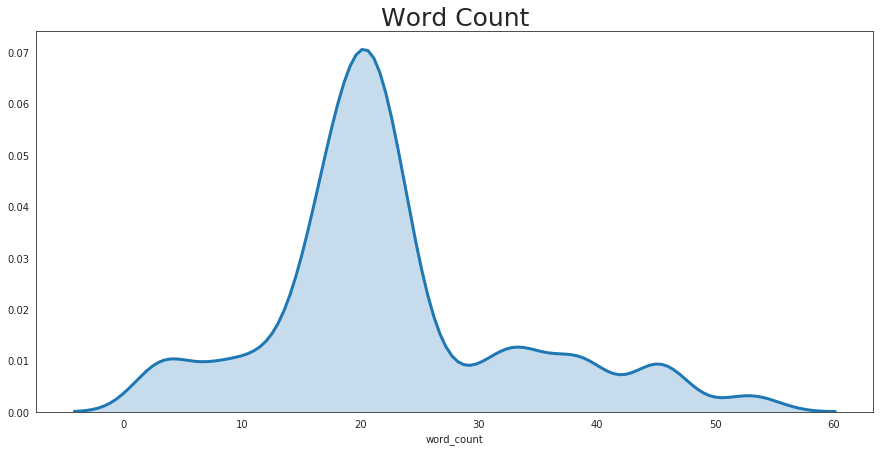

In [51]:
plt.figure(figsize= (15, 7))
sns.set_style('white')
sns.distplot(df.word_count, hist = False, kde = True, 
                 kde_kws = {'shade': True, 'linewidth': 3})
plt.title("Word Count", fontsize= 25)
plt.show()

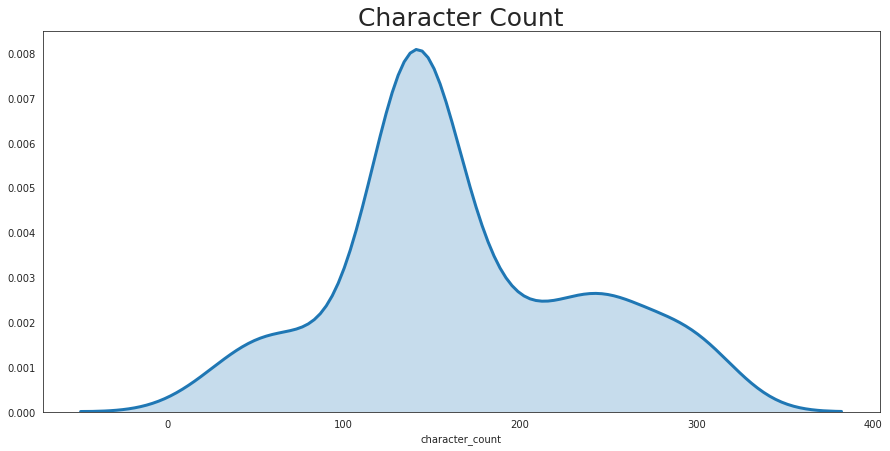

In [52]:
plt.figure(figsize= (15, 7))
sns.set_style('white')
sns.distplot(df.character_count, hist = False, kde = True, 
                 kde_kws = {'shade': True, 'linewidth': 3})
plt.title("Character Count", fontsize= 25)
plt.show()

In [0]:
import string
df['punctuation'] = [sum(char in string.punctuation for char in review) for review in df['Text']]

In [56]:
df['punctuation'].describe()

count    54.000000
mean      9.203704
std       4.341027
min       0.000000
25%       6.000000
50%       9.000000
75%      11.750000
max      22.000000
Name: punctuation, dtype: float64

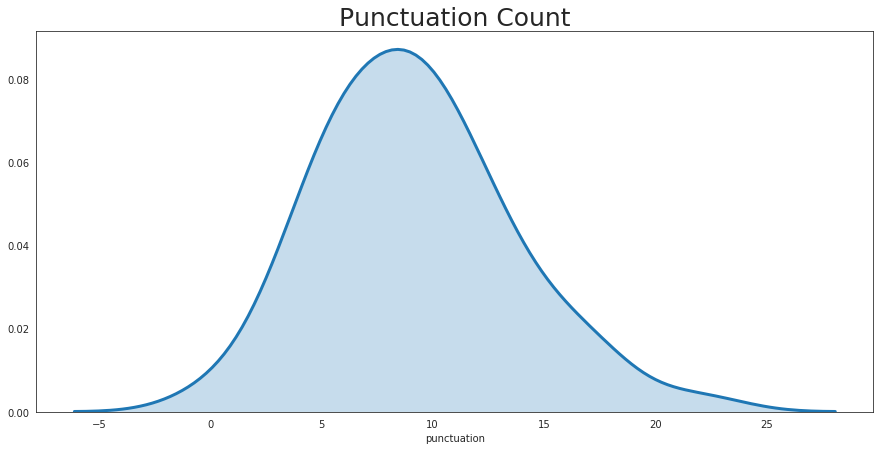

In [59]:
plt.figure(figsize= (15, 7))
sns.set_style('white')
sns.distplot(df.punctuation, hist = False, kde = True, 
                 kde_kws = {'shade': True, 'linewidth': 3})
plt.title("Punctuation Count", fontsize= 25)
plt.show()

In [61]:
getMostCommonWords(df.Text, 20)

[('the', 61),
 ('article370', 38),
 ('of', 37),
 ('to', 29),
 ('kashmir', 21),
 ('a', 21),
 ('rt', 20),
 ('in', 20),
 ('and', 17),
 ('is', 17),
 ('for', 11),
 ('issue', 9),
 ('that', 9),
 ('on', 9),
 ('has', 9),
 ('with', 7),
 ('you', 7),
 ('be', 7),
 ('we', 7),
 ('its', 7)]

In [66]:
getMostCommonWords(df.Text, 20, stopwords.words('english'))

[('article370', 38),
 ('kashmir', 21),
 ('rt', 20),
 ('issue', 9),
 ('amanhingorani', 6),
 ('pakistan', 6),
 ('abrogation', 6),
 ('news', 5),
 ('india', 5),
 ('amp', 5),
 ('world', 5),
 ('lie', 4),
 ('article', 4),
 ('ieexplained', 4),
 ('modi', 4),
 ('new', 4),
 ('state', 4),
 ('indian', 3),
 ('ask', 3),
 ('please', 3)]

In [0]:
import emoji

def extract_emojis(str):
  return ''.join(c for c in str if c in emoji.UNICODE_EMOJI)

In [0]:
df['emoticons']= df.Text.apply(extract_emojis)

In [0]:
df['emoticons_count'] = df.emoticons.apply(len)

In [74]:
df.emoticons_count.value_counts()

0    50
2     2
1     2
Name: emoticons_count, dtype: int64

*Only 4 tweets have more than 0 emoticons*

In [0]:
import string
import re
from nltk.tokenize import word_tokenize

def clean_text(text):
    # lower text
    text = text.lower()

    # Reemove Html Tags like <br>
    text= re.sub(r'<[^>]+>' , "", text)

    # remove puncutation
    text = text.translate(str.maketrans('', '', string.punctuation))

    # remove @mentions and hyperlinks
    text = re.sub(r"(?:\@|https?\://)\S+", "", text)

    # tokenize_text
    text = [word for word in word_tokenize(text)]

    # remove words that contain numbers
    text = [word for word in text if not any(c.isdigit() for c in word)]
    
    # remove empty tokens
    text = [t for t in text if len(t) > 0]

    # remove words with only one letter
    text = [t for t in text if len(t) > 1]

    # join all
    text = " ".join(text)
    return(text)

In [0]:
df["Clean_text"] = df["Text"].apply(lambda x: clean_text(x))

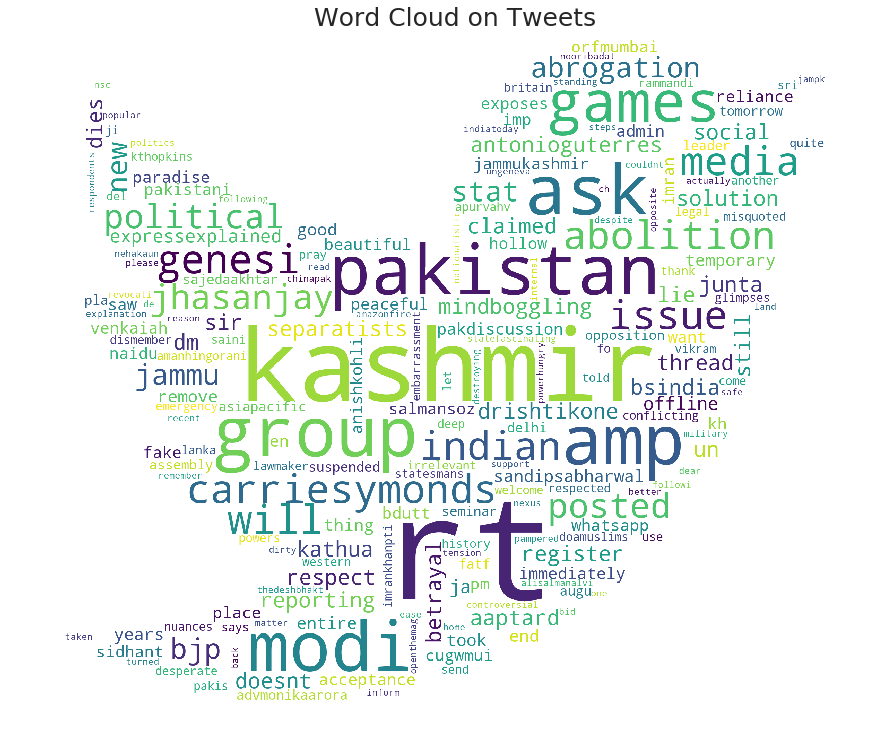

In [87]:
# Python program to generate WordCloud 
  
# importing all necessery modules 
from wordcloud import WordCloud
from os import path, getcwd
from PIL import Image
d = getcwd()
mask = np.array(Image.open(path.join(d, "twitter-logo-png-transparent.png")))  
wordcloud = WordCloud(width = 1000, height = 1000, 
                background_color ='white', 
                min_font_size = 10, mask= mask).generate(str(df.Clean_text)) 
  
# plot the WordCloud image                        
plt.figure(figsize = (12, 10), facecolor = None) 
plt.imshow(wordcloud) 
plt.axis("off") 
plt.tight_layout(pad = 0) 
plt.title("Word Cloud on Tweets", fontdict={'fontsize': 25})
plt.show()

In [0]:
from textblob import TextBlob

In [0]:
def get_senti(text):
  analysis = TextBlob(text)
  return analysis.sentiment.polarity

In [0]:
df['polarity']= df.Clean_text.apply(get_senti)

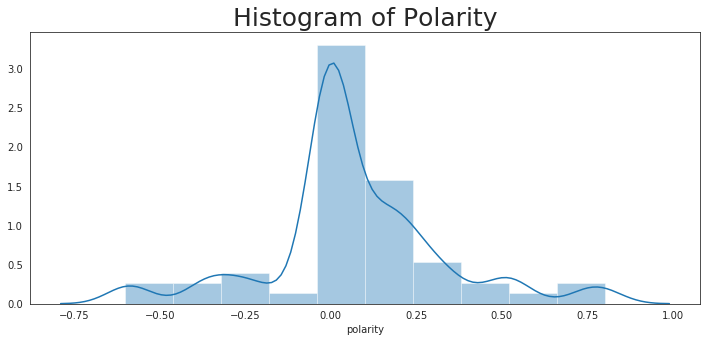

In [100]:
plt.figure(figsize= (12, 5))
sns.set_style('white')
sns.distplot(df.polarity, bins=10)
plt.title("Histogram of Polarity", fontsize= 25)
plt.show()

## Positive Tweets

In [106]:
df.loc[df.polarity >0.50, 'Text']

39     RT @anish_kohli: @BDUTT So beautiful &amp; pea...
93     Let them come. We will welcome and send them t...
149    RT @TheDeshBhakt: Dear @UNGeneva,\nPlease be i...
Name: Text, dtype: object

In [107]:
df.Text[39]

'RT @anish_kohli: @BDUTT So beautiful &amp; peaceful #Article370'

In [108]:
df.Text[93]

'Let them come. We will welcome and send them to Allah without any ticket.'

In [110]:
print(df.Text[149])

RT @TheDeshBhakt: Dear @UNGeneva,
Please be informed that you are spreading #FakeNews.
The best reporters &amp; the most senior editors have sh…


## Negative Tweets

In [111]:
df.loc[df.polarity < -0.50, 'Text']

106    @KTHopkins @ImranKhanPTI I pray that Britain o...
147                            Because of dirty politics
Name: Text, dtype: object

In [113]:
print(df.Text[106])

@KTHopkins @ImranKhanPTI I pray that Britain or for that matter any country club in the world has to see those dark insane times as seen by Kashmiri Pundits. I ask the world whats the difference between #ISIS &amp; #Pakistanis? We all in Bharat thank the world for their support for revocation of #Article370


In [114]:
print(df.Text[147])

Because of dirty politics


In [115]:
df.columns

Index(['Text', 'Creation', 'author', 'word_count', 'character_count',
       'punctuation', 'emoticons', 'emoticons_count', 'Clean_text',
       'polarity'],
      dtype='object')

In [118]:
from nltk.sentiment.vader import SentimentIntensityAnalyzer
sid = SentimentIntensityAnalyzer()
for sentence in df.Clean_text:
  print(sentence)
  ss = sid.polarity_scores(sentence)
  for k in sorted(ss):
    print('{0}: {1}, '.format(k, ss[k]), end='')
  print()
  print()

rt drishtikone mindboggling games of betrayal and intrigue and internecine rivalry of indian agencies in kashmir intrigueinkashmir arti…
compound: -0.5859, neg: 0.183, neu: 0.817, pos: 0.0, 

carriesymonds sir with all respect you will be reading me again and again until you break your silence savekashmirfrommodi kashmirbleedsunsleeps savedaughterofkashmir yasinmalik kashmirunderthreat feargod dutycalls un unspokesperson
compound: 0.4767, neg: 0.0, neu: 0.893, pos: 0.107, 

carriesymonds ask un ask antonioguterres why are they silent someone please wake them up from the deep sleep hybernation savekashmirfrommodi kashmirbleedsunsleeps savedaughterofkashmir yasinmalik kashmirunderthreat feargod dutycalls
compound: 0.3182, neg: 0.0, neu: 0.916, pos: 0.084, 

solution of kashmir issue doesnt lie in genesis of kashmir issue doesnt lie in article amanhingorani at ieexplained
compound: 0.3182, neg: 0.0, neu: 0.881, pos: 0.119, 

rt bsindia the separatists have claimed that the centres move to